In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
PROJECT_DIR = Path.cwd().parent

GROUND_DIR = PROJECT_DIR / "data" / "ground"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

print("Project folder:", PROJECT_DIR)
print("Ground data folder:", GROUND_DIR)

print("\nAvailable files:")
for file in GROUND_DIR.glob("*.csv"):
    print(file.name)

Project folder: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach
Ground data folder: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\ground

Available files:
Badulla.csv
Colombo.csv
Galle.csv
Kandy.csv
Nuwaraeliya.csv
Puttalam.csv
Station_Locations.csv


In [9]:
#Reading Badulla RainFall data
badulla_path = GROUND_DIR / "Badulla.csv"

badulla_raw = pd.read_csv(badulla_path,header=None) #Your original files are organized with months as rows and days as columns. 
#Some also contain additional header information., which we doesnt want
print("Dataset shape:", badulla_raw.shape)

display(badulla_raw.head(8))

Dataset shape: (242, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,where each value is followed by a single chara...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
2,1981-01,12.4,16.4,37.2,6.4,.0T,0,0,0,0,...,0,0,0,0,0,.0T,0.4,0.5,0,0
3,1981-02,0,0,.0T,3.8,31.3,14.6,52.8,3.2,1,...,0,.0T,0,0,0,3.3,0,NaN,NaN,NaN
4,1981-03,0,0,.0T,0,.0T,0,2.8,15.5,0,...,0,3.1,0,0,9.6,0,0,5.8,26.3,6.5
5,1981-04,0,0,0,0,1.7,9,1.4,10.7,4.5,...,0,1.5,2.5,5.5,0.8,0,6.5,2.5,17.5,NaN
6,1981-05,1.2,4.6,0,.0T,1.3,3.2,1.8,20.9,6.8,...,0,.0T,0,0.8,10.5,3.4,1.8,22,0,0
7,1981-06,0,0,0,0,0,0,0.8,0.2,0.7,...,0,0,0,0,0,0,.0T,0,0,NaN


In [11]:
#inspecting missing values
print("First 10 rows:")
display(badulla_raw.iloc[:10, :8])

print("\nLast 5 rows:")
display(badulla_raw.tail())

First 10 rows:


,0,1,2,3,4,5,6,7
0,where each value is followed by a single chara...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1,2,3,4,5,6,7
2,1981-01,12.4,16.4,37.2,6.4,.0T,0,0
3,1981-02,0,0,.0T,3.8,31.3,14.6,52.8
4,1981-03,0,0,.0T,0,.0T,0,2.8
5,1981-04,0,0,0,0,1.7,9,1.4
6,1981-05,1.2,4.6,0,.0T,1.3,3.2,1.8
7,1981-06,0,0,0,0,0,0,0.8
8,1981-07,0,0,0,0,0,.0T,0
9,1981-08,0,0,0,0,0,0,0



Last 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
237,2000-08,0.9,.0T,0,0,0,0,0,0,0,...,0,0,1.4,0.9,5.4,0,0,0,0,0
238,2000-09,0,0,0,0,0,0.2,.0T,0.6,0,...,19.3,2.2,90.9,0,2.1,23.4,50.8,0,0.8,NaN
239,2000-10,5.1,0.2,17.6,6,3.5,5.6,0,2.6,0,...,0,0,0.2,1.9,0,0,0,0,0,0.5
240,2000-11,21.2,7.4,3.4,1.2,13,0,3,12.2,0.2,...,55.2,42.1,10.6,0,1.6,1.3,0,0,0,NaN
241,2000-12,0,.0T,0,0.6,0.9,1.8,1.7,10.7,21.2,...,0.3,10.5,14.4,3.4,5.9,0,33.8,0.3,0,0


change the current monthly-row format into below
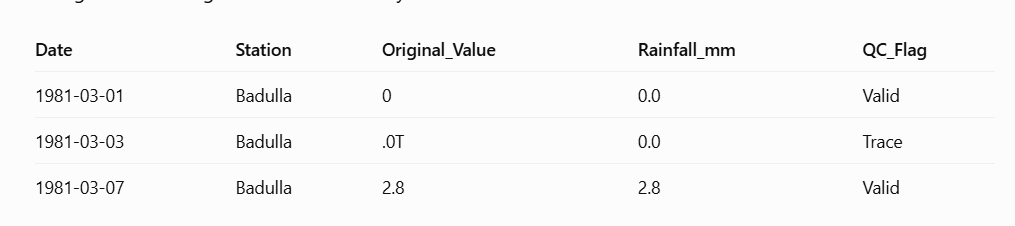


In [14]:
def clean_rainfall(value):
    """Convert a ground rainfall entry into (value_mm, QC_flag)."""

    if pd.isna(value):
        return np.nan, "Missing"

    original = str(value).strip()
    code = original.upper().replace(" ", "")

    if code in [".0T", "0.0T", ".0Y", "0.0Y"]:
        return 0.0, "Trace"

    if code in ["-9.9M", "-9.9", "", "NAN"]:
        return np.nan, "Missing"

    try:
        rainfall = float(code)

        if rainfall < 0:
            return np.nan, "Review"

        return rainfall, "Valid"

    except ValueError:
        return np.nan, "Review"

In [16]:
#Convert Badulla (or any region) into daily observations
def convert_to_daily(raw_data, station_name):

    records = []

    for _, row in raw_data.iterrows():

        month = pd.to_datetime(
            row.iloc[0], format="%Y-%m", errors="coerce"
        )

        if pd.isna(month):
            continue

        for day in range(1, month.days_in_month + 1):

            date = month + pd.Timedelta(days=day - 1)
            original = row.iloc[day]

            rainfall, flag = clean_rainfall(original)

            records.append({
                "Date": date,
                "Station": station_name,
                "Original_Value": original,
                "Rainfall_mm": rainfall,
                "QC_Flag": flag
            })

    return pd.DataFrame(records)

In [18]:
#Testing for badulla
badulla_daily = convert_to_daily(badulla_raw,"Badulla")
print("Total daily records:", len(badulla_daily))
display(badulla_daily.head(10))

print("\nQuality control summary:")
display(badulla_daily["QC_Flag"].value_counts())

Total daily records: 7305


,Date,Station,Original_Value,Rainfall_mm,QC_Flag
0,1981-01-01,Badulla,12.4,12.4,Valid
1,1981-01-02,Badulla,16.4,16.4,Valid
2,1981-01-03,Badulla,37.2,37.2,Valid
3,1981-01-04,Badulla,6.4,6.4,Valid
4,1981-01-05,Badulla,.0T,0.0,Trace
5,1981-01-06,Badulla,0,0.0,Valid
6,1981-01-07,Badulla,0,0.0,Valid
7,1981-01-08,Badulla,0,0.0,Valid
8,1981-01-09,Badulla,0,0.0,Valid
9,1981-01-10,Badulla,0,0.0,Valid



Quality control summary:


QC_Flag
Valid      6750
Trace       550
Missing       5
Name: count, dtype: int64

In [20]:
#Examine questionable observations
review_badulla = badulla_daily[badulla_daily["QC_Flag"].isin(["Missing", "Review"])]
display(review_badulla)

,Date,Station,Original_Value,Rainfall_mm,QC_Flag
2766,1988-07-29,Badulla,-9.9M,NaN,Missing
2767,1988-07-30,Badulla,-9.9M,NaN,Missing
3129,1989-07-27,Badulla,-9.9M,NaN,Missing
3130,1989-07-28,Badulla,-9.9M,NaN,Missing
5846,1997-01-03,Badulla,-9.9M,NaN,Missing


**Validate the cleaned Badulla dataset**

In [23]:
#Check the dates and missing values
print("Station:", badulla_daily["Station"].unique())

print("First date:", badulla_daily["Date"].min())
print("Last date:", badulla_daily["Date"].max())

print("Total records:", len(badulla_daily))

print("Missing rainfall values:",
      badulla_daily["Rainfall_mm"].isna().sum())

print("\nQuality control summary:")
display(badulla_daily["QC_Flag"].value_counts())

Station: <StringArray>
['Badulla']
Length: 1, dtype: str
First date: 1981-01-01 00:00:00
Last date: 2000-12-31 00:00:00
Total records: 7305
Missing rainfall values: 5

Quality control summary:


QC_Flag
Valid      6750
Trace       550
Missing       5
Name: count, dtype: int64

In [27]:
#Check duplicate dates
duplicates = badulla_daily[badulla_daily["Date"].duplicated(keep=False)]

print("Duplicate dates:", len(duplicates))
display(duplicates.head())

Duplicate dates: 0


,Date,Station,Original_Value,Rainfall_mm,QC_Flag


In [29]:
#Check suspicious rainfall values
print("Minimum rainfall:",badulla_daily["Rainfall_mm"].min())
print("Maximum rainfall:",badulla_daily["Rainfall_mm"].max())
display(
    badulla_daily[
        badulla_daily["Rainfall_mm"] > 100
    ][["Date", "Rainfall_mm", "Original_Value"]]
)

Minimum rainfall: 0.0
Maximum rainfall: 230.6


,Date,Rainfall_mm,Original_Value
707,1982-12-09,126.2,126.2
1393,1984-10-25,104.9,104.9
1830,1986-01-05,114.6,114.6
1831,1986-01-06,147.6,147.6
1832,1986-01-07,128.5,128.5
1833,1986-01-08,120.5,120.5
1834,1986-01-09,139.3,139.3
3290,1990-01-04,230.6,230.6
3667,1991-01-16,127.4,127.4
5082,1994-12-01,129.5,129.5


In [31]:
#Rainfall exceeding 100 mm/day is not automatically incorrect. We're flagging unusually high values for inspection, not deleting them.

In [33]:
#Save the cleaned Badulla dataset
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

badulla_daily.to_csv(PROCESSED_DIR / "Badulla_Cleaned.csv",index=False)
print("Badulla cleaned dataset saved successfully!")

Badulla cleaned dataset saved successfully!


In [35]:
#Define the remaining stations
stations = [
    "Colombo",
    "Galle",
    "Kandy",
    "Nuwaraeliya",
    "Puttalam"
]

print("Stations to process:")
for station in stations:
    print(station)

Stations to process:
Colombo
Galle
Kandy
Nuwaraeliya
Puttalam


In [37]:
all_stations = {}

for station in stations:

    #  Read original data
    file_path = GROUND_DIR / f"{station}.csv"
    raw = pd.read_csv(file_path, header=None)
    # Convert monthly data into daily data
    daily = convert_to_daily(raw, station)
    #Store in a dictionary
    all_stations[station] = daily

    # Step 4: Print basic information
    print(f"\nStation: {station}")
    print("Total records:", len(daily))
    print("Missing values:", daily["Rainfall_mm"].isna().sum())
    print("Duplicate dates:", daily["Date"].duplicated().sum())


Station: Colombo
Total records: 7305
Missing values: 26
Duplicate dates: 0

Station: Galle
Total records: 7305
Missing values: 14
Duplicate dates: 0

Station: Kandy
Total records: 7305
Missing values: 9
Duplicate dates: 0

Station: Nuwaraeliya
Total records: 7305
Missing values: 27
Duplicate dates: 0

Station: Puttalam
Total records: 7305
Missing values: 12
Duplicate dates: 0


In [39]:
#Dictionary - all_stations stores each station's DataFrame under its name.
#Ex- all_stations["Kandy"] - returns kandy clean data frame

In [41]:
#Create a quality control summary table
qc_results = []

for station, df in all_stations.items():

    qc_results.append({
        "Station": station,
        "Start_Date": df["Date"].min(),
        "End_Date": df["Date"].max(),
        "Total_Days": len(df),
        "Valid_Days": df["Rainfall_mm"].notna().sum(),
        "Missing_Days": df["Rainfall_mm"].isna().sum(),
        "Trace_Days": (df["QC_Flag"] == "Trace").sum(),
        "Review_Days": (df["QC_Flag"] == "Review").sum(),
        "Duplicate_Dates": df["Date"].duplicated().sum()
    })

qc_summary = pd.DataFrame(qc_results)

display(qc_summary)

,Station,Start_Date,End_Date,Total_Days,Valid_Days,Missing_Days,Trace_Days,Review_Days,Duplicate_Dates
0,Colombo,1981-01-01,2000-12-31,7305,7279,26,0,1,0
1,Galle,1981-01-01,2000-12-31,7305,7291,14,0,2,0
2,Kandy,1981-01-01,2000-12-31,7305,7296,9,3,3,0
3,Nuwaraeliya,1981-01-01,2000-12-31,7305,7278,27,2,26,0
4,Puttalam,1981-01-01,2000-12-31,7305,7293,12,0,1,0


In [43]:
#Inspect entries requiring manual review
review_records = []

for station, df in all_stations.items():

    flagged = df[df["QC_Flag"] == "Review"]
    if not flagged.empty:
        review_records.append(flagged)

if review_records:
    review_table = pd.concat(review_records,ignore_index=True)
    display(review_table)
else:
    print("No unknown rainfall codes requiring review.")

,Date,Station,Original_Value,Rainfall_mm,QC_Flag
0,1994-03-05,Colombo,T 3.0,NaN,Review
1,1983-05-05,Galle,T .0,NaN,Review
2,1983-06-05,Galle,T 3.0,NaN,Review
3,1982-02-14,Kandy,.0 .,NaN,Review
4,1982-02-22,Kandy,.0 .,NaN,Review
5,1984-06-22,Kandy,.9T,NaN,Review
6,1982-11-05,Nuwaraeliya,T 3.1,NaN,Review
7,1983-05-05,Nuwaraeliya,T 23.6,NaN,Review
8,1983-06-05,Nuwaraeliya,T .0,NaN,Review
9,1983-10-05,Nuwaraeliya,T .1,NaN,Review


In [45]:
#Save the five cleaned datasets
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

for station, df in all_stations.items():

    output_path = PROCESSED_DIR / f"{station}_Cleaned.csv"

    df.to_csv(output_path, index=False)

    print("Saved:", output_path.name)

Saved: Colombo_Cleaned.csv
Saved: Galle_Cleaned.csv
Saved: Kandy_Cleaned.csv
Saved: Nuwaraeliya_Cleaned.csv
Saved: Puttalam_Cleaned.csv


In [47]:
#save the quality control summary
qc_summary.to_csv(PROCESSED_DIR / "Ground_QC_Summary.csv",index=False)
print("Quality control summary saved!")

Quality control summary saved!


In [49]:
#Combine all six stations - Finally, add Badulla to our dictionary and create one combined dataset.
all_stations["Badulla"] = badulla_daily

combined_ground = pd.concat(all_stations.values(),ignore_index=True)
combined_ground = combined_ground.sort_values( ["Station", "Date"]).reset_index(drop=True)
display(combined_ground.head())

print("Total records:", len(combined_ground))
print("Number of stations:", combined_ground["Station"].nunique())

,Date,Station,Original_Value,Rainfall_mm,QC_Flag
0,1981-01-01,Badulla,12.4,12.4,Valid
1,1981-01-02,Badulla,16.4,16.4,Valid
2,1981-01-03,Badulla,37.2,37.2,Valid
3,1981-01-04,Badulla,6.4,6.4,Valid
4,1981-01-05,Badulla,.0T,0.0,Trace


Total records: 43830
Number of stations: 6


In [51]:
#To save combined
combined_ground.to_csv(PROCESSED_DIR / "All_Stations_Ground_Cleaned.csv",index=False)
print("Combined ground dataset saved!")

Combined ground dataset saved!


In [53]:
#Check all unusual rainfall entries
review_all = combined_ground[combined_ground["QC_Flag"] == "Review"].copy()
display(review_all[ ["Station", "Date", "Original_Value", "QC_Flag"]].sort_values(["Station", "Date"]))
print("Total entries needing review:", len(review_all))

,Station,Date,Original_Value,QC_Flag
12116,Colombo,1994-03-05,T 3.0,Review
15464,Galle,1983-05-05,T .0,Review
15495,Galle,1983-06-05,T 3.0,Review
22324,Kandy,1982-02-14,.0 .,Review
22332,Kandy,1982-02-22,.0 .,Review
23183,Kandy,1984-06-22,.9T,Review
29893,Nuwaraeliya,1982-11-05,T 3.1,Review
30074,Nuwaraeliya,1983-05-05,T 23.6,Review
30105,Nuwaraeliya,1983-06-05,T .0,Review
30227,Nuwaraeliya,1983-10-05,T .1,Review


Total entries needing review: 33
